# E202D · LiDAR, stability calibration, and 32-minibatch LR decisions

**Complete** · D1–D2 and D3 advancement assessment saved · 1/1

**Estimated finish for D1–D2** · Wednesday 18 November, 09:03 Stockholm · approximately 0.0 hours remaining. The initial range is ±30%, updated from observed update, health-assay, and branch runtimes. D3 is conditional and adds approximately 1–3 hours if enabled. A computer restart interrupts this estimate.

Updated 2026-11-18T09:03:20.415733+01:00. Completed branch files are resumable. There are 0 of 432 branches left. The worker flushes checkpoint and status writes and retains one active full learner checkpoint. Reopen this notebook for the latest saved snapshot.

## Registered design

D1 rebuilds the six conservative, aggressive, and periodic-conservative source trajectories. It reads eight views of 128 images on each of two independent fixed banks and shares the embeddings across LiDAR, discriminant spectrum strength, soft retrieval, margins, alignment, RankMe, centered rank and normalized dispersion. At early and final checkpoints it checks a separate 512-image bank. LiDAR is tested with relative regularizers 0.001, 0.01, and 0.1, four versus eight views, and 64-image subsamples. Its 128-image discriminant spectrum has at most 127 nonzero dimensions. The primary regularizer is fixed at 0.01. [LiDAR paper](https://arxiv.org/abs/2312.04000).

The earlier study retained full model checkpoints at minibatch 423 and summary readouts at other points. D1 therefore rebuilds trajectories and caches embeddings. External frozen probes are read only for research validation. Their labels are excluded from action predictors, safety thresholds, and deployed decisions.

D2 covers **48 states across six seeds**, with eight states per seed. Every seed includes early, middle and late checkpoints and all three origins. One of the nine origin/stage combinations per seed is omitted by a fixed counterbalanced rule. Every retained state has three paired fresh augmentation draws, three actions, a 32-minibatch intervention, and a 32-minibatch common conservative continuation. This makes **432 branches**. All actions restore backbone, heads, normalization buffers, AdamW moments and AMP scaler. Skip advances the stream and preserves learner state. The six seeds share the prior pretrained backbone and settled heads. Missing source trajectories are reconstructed.

Safety uses relative rank and margin deterioration limits, a cumulative budget, and absolute empirical floors calibrated on four periodic-conservative development trajectories. Seeds 5–6 and the independent bank assess false alarms. These empirical floors require validation before deployment. Already-outside states must predict recovery. Repeated smaller losses are checked against cumulative limits.

Constant, recent-trend, and ridge predictors are fit using seeds 1–4 and evaluated on 5–6. Ridge regularization uses seed-held-out development folds. Separate action-conditioned outputs predict maximum observed rank/margin deterioration at the initial state, intervention endpoint, and 16/32 continuation minibatches, endpoint changes, candidate learning gains, and layer-wise CKA. Action regret and unsafe choices are tested using the third augmentation draw after decisions are formed from the first two. Bootstrap intervals resample entire seeds. The LiDAR learning controller additionally requires positive external agreement on held-out trajectories and selected branch probes. Fixed schedules and a reactive filter are the prospective baselines.

## Recalibrated stability

```json
{
  "monitor": {
    "rank_floor": 48.32960891723633,
    "margin_floor": 0.03801962733268738,
    "rank_deterioration": 0.005734094410211569,
    "margin_deterioration": 0.017810697921263722,
    "cumulative_rank": 0.13316358297104872,
    "cumulative_margin": 0.0,
    "holdout_violation": {
      "5": 0.0,
      "6": 0.0
    },
    "method": "healthy trajectory minima minus between-seed range",
    "fitted_seeds": [
      1,
      2,
      3,
      4
    ],
    "evaluated_seeds": [
      5,
      6
    ]
  },
  "audit": {
    "rank_floor": 47.914878845214844,
    "margin_floor": 0.038304537534713745,
    "rank_deterioration": 0.005866389097124103,
    "margin_deterioration": 0.017617566377781772,
    "cumulative_rank": 0.13777524065119306,
    "cumulative_margin": 0.0,
    "holdout_violation": {
      "5": 0.0,
      "6": 0.0
    },
    "method": "healthy trajectory minima minus between-seed range",
    "fitted_seeds": [
      1,
      2,
      3,
      4
    ],
    "evaluated_seeds": [
      5,
      6
    ]
  }
}
```

## Held-out action prediction

```json
{
  "alpha": 100.0,
  "fit_seeds": [
    1,
    2,
    3,
    4
  ],
  "test_seeds": [
    5,
    6
  ],
  "rmse": {
    "constant": {
      "rank_loss": 0.014134118642084742,
      "margin_loss": 0.03436875949994493,
      "rank_end": 0.016308342535918726,
      "margin_end": 0.04377836306609832,
      "lidar_gain": 0.7534138272984015,
      "margin_gain": 0.0011733842251364852,
      "block_01": 0.0011790629810780149,
      "block_02": 0.001515310659654275,
      "block_03": 0.0011093066068874873,
      "block_04": 0.0007565360224259162,
      "block_05": 0.001116397103174929,
      "block_06": 0.002242273196005685,
      "block_07": 0.004539580972858641,
      "block_08": 0.011677095722835049,
      "block_09": 0.015675274815662374,
      "block_10": 0.015375578631639276,
      "block_11": 0.01752678921045211,
      "block_12": 0.019859797418778025
    },
    "trend": {
      "rank_loss": 0.02030358304680458,
      "margin_loss": 0.037027321330463325,
      "rank_end": 0.027298918249605706,
      "margin_end": 0.047484307332459154,
      "lidar_gain": 0.9634232433757591,
      "margin_gain": 0.0012835114069421384,
      "block_01": 0.0015747866458226544,
      "block_02": 0.0020769235528208837,
      "block_03": 0.0015371777935152676,
      "block_04": 0.0010282883319912945,
      "block_05": 0.0014389842216315446,
      "block_06": 0.002903968659479889,
      "block_07": 0.005711011958366774,
      "block_08": 0.015318044083160282,
      "block_09": 0.021816442663472126,
      "block_10": 0.02487346859891102,
      "block_11": 0.030028581790779087,
      "block_12": 0.03011616834739229
    },
    "ridge": {
      "rank_loss": 0.01380718041062204,
      "margin_loss": 0.031052246312791052,
      "rank_end": 0.015588775103317633,
      "margin_end": 0.04189359440651531,
      "lidar_gain": 0.9650268478382421,
      "margin_gain": 0.0010534360017477767,
      "block_01": 0.0012973092923966474,
      "block_02": 0.0014476302695140362,
      "block_03": 0.0010965506982943815,
      "block_04": 0.0007498876824612644,
      "block_05": 0.001091816480184892,
      "block_06": 0.002033312641397798,
      "block_07": 0.004512929542690995,
      "block_08": 0.011725416122219575,
      "block_09": 0.015266134406273429,
      "block_10": 0.014260898014343625,
      "block_11": 0.016144902585833988,
      "block_12": 0.018510860333075647
    }
  },
  "action_loss_improvement": {
    "mean": 0.0,
    "lower": 0.0,
    "upper": 0.0
  },
  "unsafe_rate": 0.5,
  "constant_unsafe_rate": 0.5,
  "states": 16,
  "paired_seed_benefits": [
    0.0,
    0.0
  ],
  "uncertainty": [
    0.020345345224118263,
    0.04492450985055659,
    0.022685425859545274,
    0.052294231908938185,
    2.055517312804726,
    0.0016128213257093284,
    0.0025667358978581868,
    0.0024242380250278452,
    0.0020797364515361206,
    0.0015760103197831991,
    0.002101783032429314,
    0.003344962232771016,
    0.0058501296350218215,
    0.016468456437620096,
    0.01816481762385888,
    0.022099786478729594,
    0.03679431349195097,
    0.04699350389855211
  ],
  "loss_definition": "Normalized shortfall in permitted intensity against a two-draw oracle. Safety is evaluated separately.",
  "note": "Two held-out seeds give limited interval precision"
}
```

## LiDAR estimator sensitivity

```json
{
  "small_images": 128,
  "large_images": 512,
  "views": 8,
  "small_spectrum_ceiling": 127,
  "regularizers": [
    0.001,
    0.01,
    0.1
  ],
  "estimates": 54,
  "small_large_spearman": 0.9875722314572946,
  "median_relative_regularizer_range": 0.1271622457904566,
  "median_relative_four_view_change": 0.06925158013537631,
  "median_relative_subset_change": 0.4028592915975955
}
```

## External learning-proxy assessment

```json
{
  "delta_spearman": {
    "lidar": {
      "5": {
        "scene": 0.23219814241486067,
        "weather": -0.10835913312693499
      },
      "6": {
        "scene": 0.3684210526315789,
        "weather": 0.2776057791537668
      }
    },
    "spectrum_strength": {
      "5": {
        "scene": -0.0608875128998968,
        "weather": -0.2053663570691434
      },
      "6": {
        "scene": 0.35810113519091846,
        "weather": 0.2961816305469556
      }
    },
    "soft_retrieval": {
      "5": {
        "scene": 0.054695562435500514,
        "weather": 0.16408668730650156
      },
      "6": {
        "scene": 0.1042311661506708,
        "weather": 0.36429308565531476
      }
    },
    "margin": {
      "5": {
        "scene": -0.15376676986584106,
        "weather": 0.06707946336429307
      },
      "6": {
        "scene": 0.2693498452012384,
        "weather": 0.43446852425180604
      }
    },
    "alignment": {
      "5": {
        "scene": -0.28998968008255926,
        "weather": -0.20123839009287925
      },
      "6": {
        "scene": -0.4592363261093911,
        "weather": 0.17647058823529413
      }
    }
  },
  "lidar_external_pass": false,
  "selected_branch_states": 11,
  "lidar_action_scene_regret": 0.008258769745206562,
  "labels_used": "External assessment only. No supervised fitting of action predictors."
}
```

## D3 advancement

```json
{
  "calibration_pass": true,
  "action_selection_pass": false,
  "protective_deployment": false,
  "learning_deployment": false
}
```



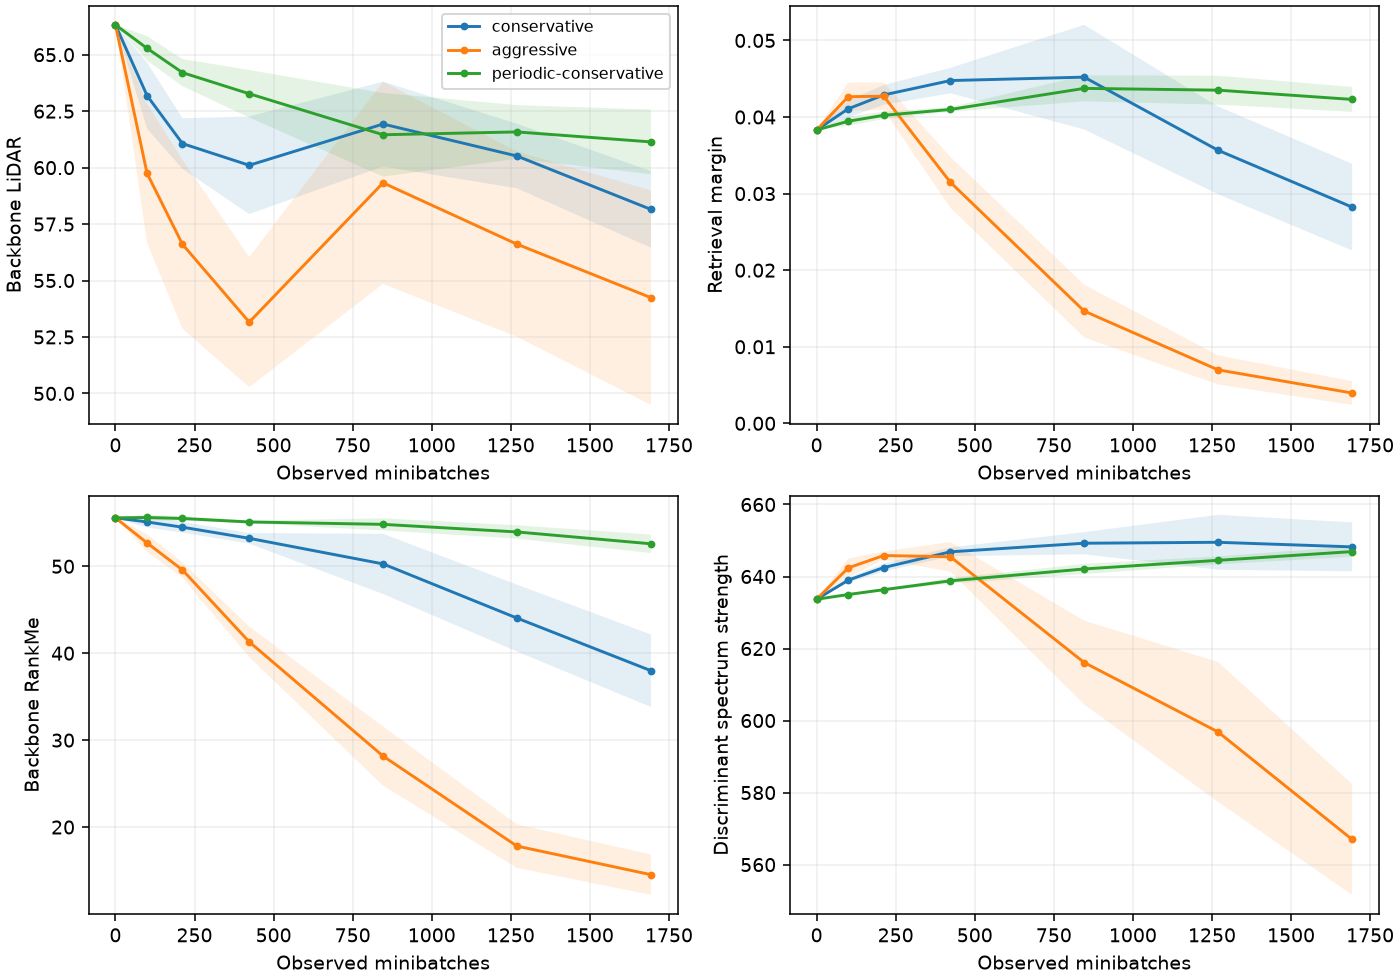